# Stroke Prediction Capstone Project

This notebook documents data inspection and cleaning, exploratory data analysis (EDA), preprocessing, training of four classification models, evaluation of their performance, and a comparison of the results. The target variable is `stroke` (0 = no stroke, 1 = stroke).

**Important limitation:** this is an educational machine-learning project, not a clinically validated diagnostic tool. Results must be interpreted carefully because stroke cases are uncommon in this dataset.

**How to run:** use *Run all* (or run every cell from top to bottom, in order). Later cells depend on variables created in earlier cells.

**AI assistance note:** parts of this notebook were written with the assistance of Claude (Anthropic) and adapted for this dataset.

### Contents
1. Setup and Imports
2. Loading the Dataset
3. Data Inspection and Cleaning
4. Exploratory Data Analysis
5. Data Preprocessing
6. Model Training
7. Model Evaluation
8. Model Comparison and Discussion
9. References

## 1. Setup and Imports

All libraries are imported once, here, so that the rest of the notebook can use them without repeating imports. The main libraries are pandas (McKinney, 2010) and NumPy (Harris et al., 2020) for data handling, Matplotlib (Hunter, 2007) and seaborn (Waskom, 2021) for plots, scikit-learn (Pedregosa et al., 2011) for preprocessing, models and metrics, and XGBoost (Chen & Guestrin, 2016) for gradient boosting.

In [ ]:
# Data handling and numerical work
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Used to display tables and formatted text inside the notebook
from IPython.display import Markdown, display

# Splitting the data and building the preprocessing pipeline
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import clone

# The four classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Evaluation metrics and plotting helpers
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    roc_auc_score,
)

# A clean, readable default style for every plot in the notebook
sns.set_theme(style="whitegrid")

## 2. Loading the Dataset

The dataset is the public *Stroke Prediction Dataset* (Fedesoriano, 2021). The cell below looks for the CSV file in the current folder, in `/content`, and in Google Drive (`MyDrive`). If it is not found locally, it mounts Google Drive (this only works in Google Colab). The file is read **once**, and two copies are kept:

- `raw_df` is the untouched source data. It is used for modelling, so that nothing learned from the test set can leak into preprocessing.
- `df` is a working copy that is cleaned and explored in sections 3 and 4.

In [ ]:
from pathlib import Path

# The file may be saved with a space or an underscore in its name, so both are tried
DATASET_FILENAMES = [
    "healthcare-dataset-stroke-data 3.csv",
    "healthcare-dataset-stroke-data_3.csv",
]
SEARCH_FOLDERS = [Path("."), Path("/content"), Path("/content/drive/MyDrive")]


def find_dataset():
    """Return the path of the first matching CSV file, or None if none exists."""
    for folder in SEARCH_FOLDERS:
        for filename in DATASET_FILENAMES:
            if (folder / filename).exists():
                return folder / filename
    return None


csv_path = find_dataset()

# If the file was not found locally, try mounting Google Drive (Colab only)
if csv_path is None:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        csv_path = find_dataset()
    except ImportError:
        pass  # Not running in Colab, so there is no Drive to mount

if csv_path is None:
    raise FileNotFoundError(
        f"Could not find any of {DATASET_FILENAMES}. Place the CSV next to this "
        "notebook, in /content, or in Google Drive under MyDrive, then run again."
    )

raw_df = pd.read_csv(csv_path)  # untouched copy, used for modelling
df = raw_df.copy()              # working copy for cleaning and EDA

print("Loaded dataset from:", csv_path)
print("Dataset shape:", df.shape)

Loaded dataset from: /content/drive/MyDrive/healthcare-dataset-stroke-data 3.csv
Dataset shape: (5110, 12)


## 3. Data Inspection and Cleaning

This section checks the structure and quality of the data before any modelling. Cleaning steps are applied to the working copy `df` only. The modelling section starts again from `raw_df`.

### 3.1 Initial Dataset Inspection

In [ ]:
# First five rows: a quick look at the variables and how values are recorded
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
# Column names, data types, and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [ ]:
# Summary statistics (count, mean, spread, quartiles) of the numerical variables
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


The dataset was loaded into a pandas DataFrame and inspected using `head()`, `info()` and `describe()`. It contains 5,110 observations and 12 variables covering demographic, health, lifestyle and stroke-related information. The target variable is `stroke`, where 0 indicates no stroke and 1 indicates a stroke.

### 3.2 Checking Missing Values

In [ ]:
# Number and percentage of missing values in every column
missing_summary = pd.DataFrame({
    "Missing values": df.isnull().sum(),
    "Percentage (%)": (df.isnull().mean() * 100).round(2),
})
missing_summary

,Missing values,Percentage (%)
id,0,0.00
gender,0,0.00
age,0,0.00
hypertension,0,0.00
heart_disease,0,0.00
ever_married,0,0.00
work_type,0,0.00
Residence_type,0,0.00
avg_glucose_level,0,0.00
bmi,201,3.93


Only `bmi` has missing values (201 observations, about 3.93% of the data). All other columns are complete.

### 3.3 Investigating BMI Before Imputation

The histogram below shows the BMI distribution **before** the missing values are filled. Summary statistics are in the `describe()` output above and in the next cell.

BMI median: 28.10
BMI mean:   28.89
BMI skewness: 1.06  (positive = long right tail)


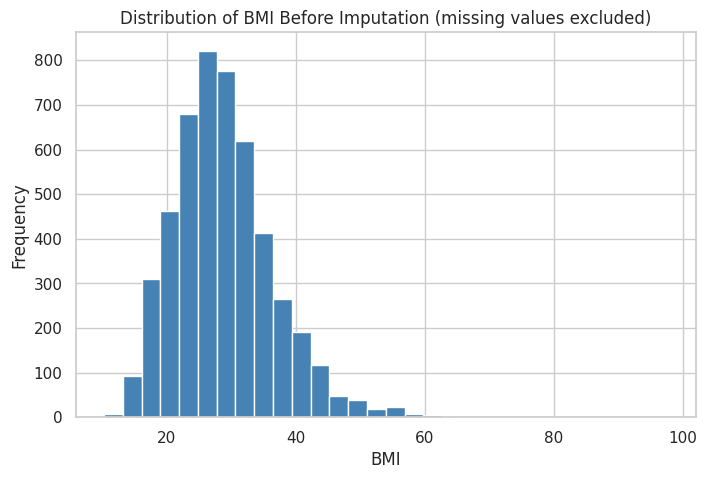

In [ ]:
# Median and mean BMI, ignoring the missing values
print(f"BMI median: {df['bmi'].median():.2f}")
print(f"BMI mean:   {df['bmi'].mean():.2f}")
print(f"BMI skewness: {df['bmi'].skew():.2f}  (positive = long right tail)")

# Histogram of the observed BMI values (missing values are ignored automatically)
plt.figure(figsize=(8, 5))
plt.hist(df["bmi"].dropna(), bins=30, color="steelblue", edgecolor="white")
plt.title("Distribution of BMI Before Imputation (missing values excluded)")
plt.xlabel("BMI")
plt.ylabel("Frequency")
plt.show()

The median BMI is about 28.1 and the mean is about 28.89. BMI is right-skewed (a long tail of high values), so the mean is pulled upwards by extreme values. The median is less sensitive to such values, so median imputation is a reasonable choice.

### 3.4 Filling Missing BMI Values (Exploratory Copy Only)

The 201 missing BMI values are filled with the median BMI (28.1) so that the exploratory plots and outlier checks in this notebook can use every row.

**Modelling safeguard:** this imputation is for exploration only. The modelling section starts again from `raw_df`. There, BMI imputation, categorical encoding and numerical scaling are learned inside each model's preprocessing pipeline using the **training data only**. This stops information from the held-out test set from influencing preprocessing (data leakage).

In [ ]:
# Fill missing BMI with the median (exploratory copy only)
bmi_median = df["bmi"].median()
df["bmi"] = df["bmi"].fillna(bmi_median)

# Check: this should print 0
print("Missing BMI values after imputation:", df["bmi"].isnull().sum())

Missing BMI values after imputation: 0


### 3.5 Removing the ID Column

The `id` variable is a record identifier rather than a meaningful health or demographic feature. It carries no useful information for predicting stroke and could introduce irrelevant noise, so it is removed from the exploratory copy. (It is also removed from the modelling data in section 5.)

In [ ]:
# Drop the identifier column from the exploratory copy
df = df.drop(columns=["id"])

# Check that it is gone
print("ID column present:", "id" in df.columns)
print("Current shape:", df.shape)

ID column present: False
Current shape: (5110, 11)


### 3.6 Identifying Numerical and Categorical Variables

The variable types are inspected first, so that the categorical variables can be examined before any encoding decisions are made.

In [ ]:
# Data type of every column
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
ever_married,object
work_type,object
Residence_type,object
avg_glucose_level,float64
bmi,float64
smoking_status,object


In [ ]:
# Numerical and categorical columns.
# "exclude number" is used for the categorical columns because newer pandas versions
# store text columns as a dedicated string type rather than "object".
numerical_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(exclude="number").columns.tolist()

print("Numerical columns: ", numerical_cols)
print("Categorical columns:", categorical_cols)

Numerical columns:  ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'stroke']
Categorical columns: ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']


### 3.7 Checking the Categorical Variables

The categories of every categorical variable are inspected before deciding how to treat them, rather than changing values blindly.

In [ ]:
# Frequency of each category in every categorical variable
for column in categorical_cols:
    print(f"\n{column}")
    print(df[column].value_counts())


gender
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

ever_married
ever_married
Yes    3353
No     1757
Name: count, dtype: int64

work_type
work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64

Residence_type
Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64

smoking_status
smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64


### 3.8 Inspecting the "Other" Gender Category

The `gender` variable contains a single observation labelled `"Other"`. It is shown below.

In [ ]:
# The single record with gender = "Other"
df[df["gender"] == "Other"]

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
3116,Other,26.0,0,0,No,Private,Rural,143.33,22.4,formerly smoked,0


This is a valid categorical response, and there is no evidence that the record is an error or a duplicate, so it was **retained**. Removing an observation only because it is uncommon would discard information. With only one such record, the model cannot learn a reliable pattern for this category, so it should not be over-interpreted.

### 3.9 Checking for Duplicates

In [ ]:
# Number of fully duplicated rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


No duplicate rows were found, so no observations were removed.

### 3.10 Checking the Target Imbalance

This check is important because stroke cases are rare, which affects how the models must be trained and evaluated.

Class counts:
stroke
0    4861
1     249
Name: count, dtype: int64

Class percentages:
stroke
0    95.13
1     4.87
Name: proportion, dtype: float64


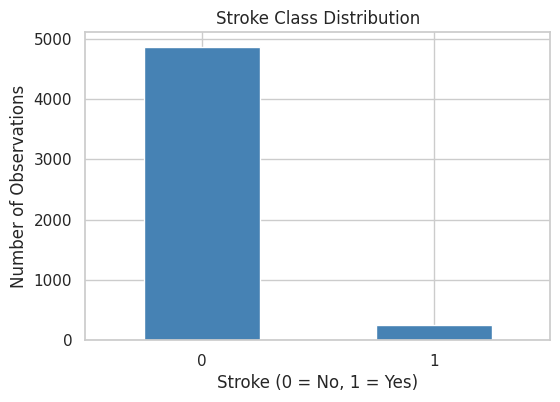

In [ ]:
# Class counts and percentages
print("Class counts:")
print(df["stroke"].value_counts())
print("\nClass percentages:")
print((df["stroke"].value_counts(normalize=True) * 100).round(2))

# Bar chart of the class distribution
plt.figure(figsize=(6, 4))
df["stroke"].value_counts().sort_index().plot(kind="bar", color="steelblue")
plt.title("Stroke Class Distribution")
plt.xlabel("Stroke (0 = No, 1 = Yes)")
plt.ylabel("Number of Observations")
plt.xticks(rotation=0)
plt.show()

The target variable `stroke` is substantially imbalanced. Of the 5,110 observations, 4,861 (95.13%) belong to the non-stroke class and only 249 (4.87%) belong to the stroke class. A model could reach high overall accuracy simply by predicting "no stroke" for everyone. Precision, recall, F1-score and the confusion matrix are therefore needed in addition to accuracy.

### 3.11 Detecting Numerical Outliers (IQR Method)

Outliers are checked for the three continuous variables: `age`, `avg_glucose_level` and `bmi`. A value is flagged when it lies more than 1.5 times the interquartile range (IQR) below the first quartile or above the third quartile. These counts use the exploratory copy, in which missing BMI has already been filled.

In [ ]:
numerical_columns = ["age", "avg_glucose_level", "bmi"]

# Quartiles and the IQR for each continuous variable
Q1 = df[numerical_columns].quantile(0.25)
Q3 = df[numerical_columns].quantile(0.75)
IQR = Q3 - Q1

# Standard 1.5 x IQR fences
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower bounds:")
print(lower_bound)
print("\nUpper bounds:")
print(upper_bound)

# Count how many values fall outside the fences in each column
outlier_counts = ((df[numerical_columns] < lower_bound) | (df[numerical_columns] > upper_bound)).sum()
print("\nNumber of potential outliers:")
print(outlier_counts)

Lower bounds:
age                 -29.0000
avg_glucose_level    21.9775
bmi                  10.3000
dtype: float64

Upper bounds:
age                  115.0000
avg_glucose_level    169.3575
bmi                   46.3000
dtype: float64

Number of potential outliers:
age                    0
avg_glucose_level    627
bmi                  126
dtype: int64


The IQR method found no outliers for age, 627 potential outliers for average glucose level, and 126 for BMI. These observations were **retained**. An IQR-based outlier is not necessarily an incorrect value, and in a healthcare dataset unusually high glucose or BMI values may be genuine patient characteristics that carry information about stroke risk. Observations were therefore not removed unless there was evidence of a data-entry error.

### 3.12 Final Data-Quality Check

In [ ]:
# One last look at the exploratory copy before the EDA
print("Dataset shape:", df.shape)
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nColumns:", df.columns.tolist())

Dataset shape: (5110, 11)

Missing values per column:
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

Duplicate rows: 0

Columns: ['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']


## 4. Exploratory Data Analysis

Exploratory data analysis (EDA) is used to inspect distributions, category frequencies, and relationships between the features and the stroke target. These plots are descriptive and are **not** evidence of causation. The exploratory copy `df` is used here; the modelling section uses the untouched `raw_df` with a leakage-safe preprocessing pipeline.

### 4.1 Numerical Features

#### Distribution of Age

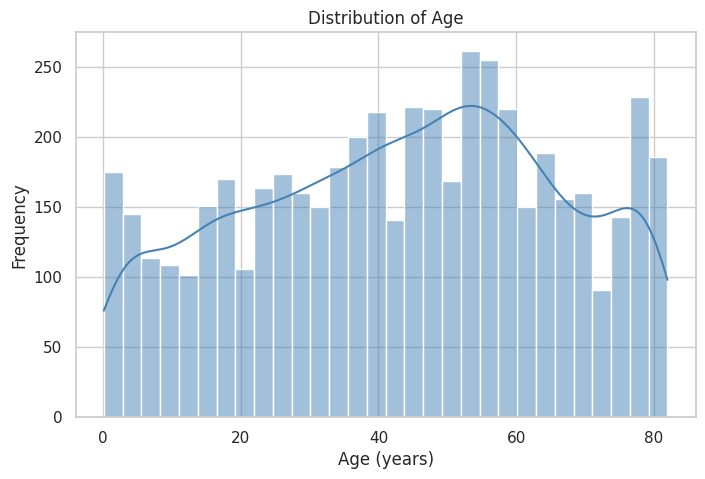

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="age", bins=30, kde=True, color="steelblue")
plt.title("Distribution of Age")
plt.xlabel("Age (years)")
plt.ylabel("Frequency")
plt.show()

**Observation: age.** Ages range from infants (the minimum is 0.08 years) to 82, with a mean of about 43. There are both young and older participants, and many adults between roughly 25 and 60. Age is a well-known stroke risk factor and has a broad numerical range, so it is kept as a numerical feature and standardised during preprocessing (standardisation matters mainly for models that are sensitive to feature scale, such as Logistic Regression).

#### Distribution of Average Glucose Level

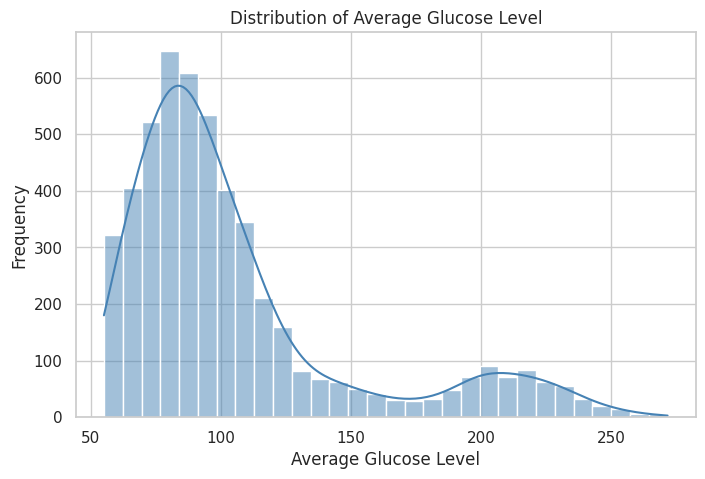

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="avg_glucose_level", bins=30, kde=True, color="steelblue")
plt.title("Distribution of Average Glucose Level")
plt.xlabel("Average Glucose Level")
plt.ylabel("Frequency")
plt.show()

**Observation: average glucose level.** The distribution is right-skewed, with most observations at lower glucose levels and a smaller number at substantially higher values. These high values may be genuine measurements rather than errors, so the potential outliers found during cleaning were retained.

#### Distribution of BMI

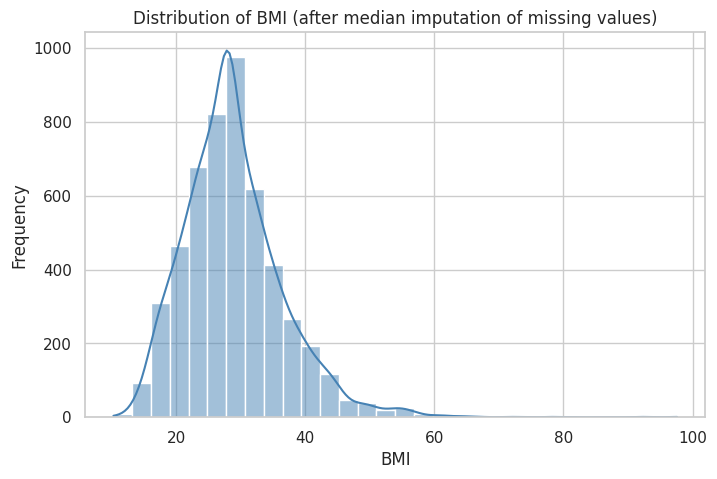

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="bmi", bins=30, kde=True, color="steelblue")
plt.title("Distribution of BMI (after median imputation of missing values)")
plt.xlabel("BMI")
plt.ylabel("Frequency")
plt.show()

**Observation: BMI.** BMI is concentrated around the middle range, with a right tail of high values. This plot is drawn **after** the 201 missing values were filled with the median (28.1), so the peak near 28 is slightly inflated by the imputation. The right tail supports using the median rather than the mean. BMI outliers were retained because they may be genuine patient values.

### 4.2 Categorical and Binary Features

#### Gender

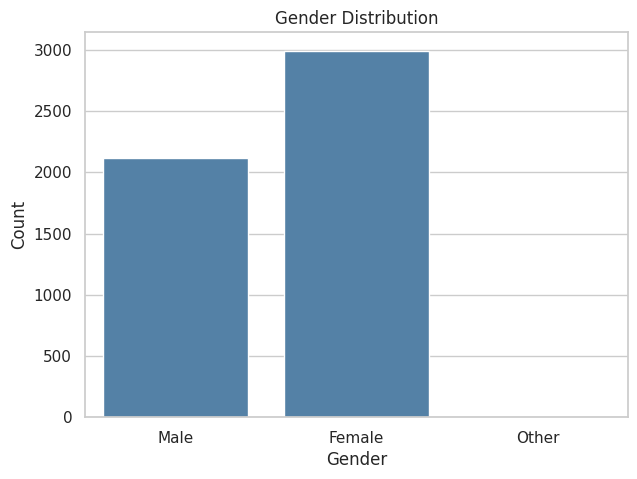

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="gender", color="steelblue")
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

**Observation: gender.** There are more female (2,994) than male (2,115) observations, and the `"Other"` category contains a single observation. That observation was retained because there is no evidence it is erroneous. Gender stays in the data as a categorical predictor.

#### Hypertension

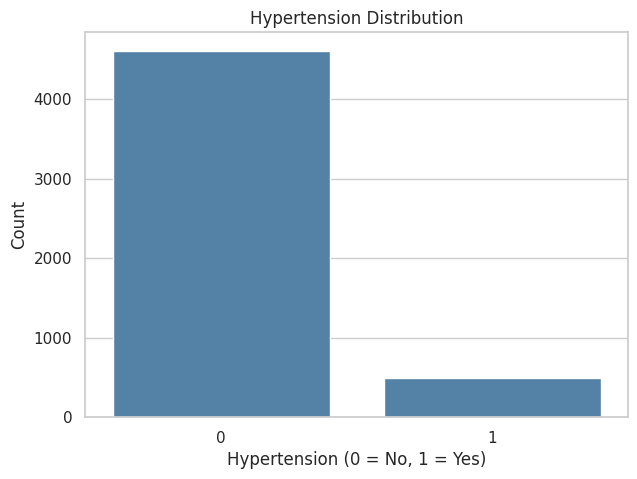

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="hypertension", color="steelblue")
plt.title("Hypertension Distribution")
plt.xlabel("Hypertension (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

**Observation: hypertension.** Most observations do not have hypertension, while a smaller proportion (498 of 5,110) do. Hypertension is a recognised stroke risk factor, so it is kept as a predictor. Its usefulness is judged by the model results, not by how balanced the feature is.

#### Heart Disease

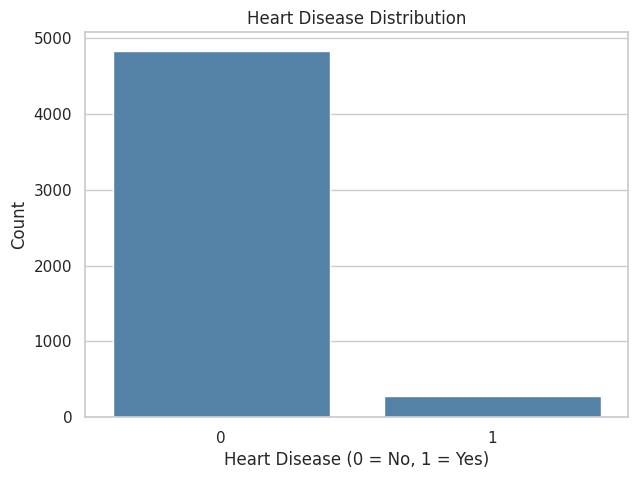

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="heart_disease", color="steelblue")
plt.title("Heart Disease Distribution")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

**Observation: heart disease.** Most observations do not have heart disease, while a smaller proportion (276 of 5,110) do. Heart disease is a recognised stroke risk factor, so it is kept as a predictor. Its usefulness is judged by the model results, not by how balanced the feature is.

#### Ever Married

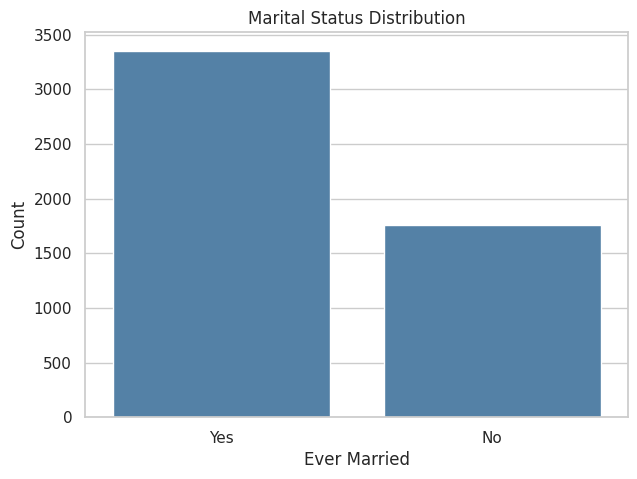

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="ever_married", color="steelblue")
plt.title("Marital Status Distribution")
plt.xlabel("Ever Married")
plt.ylabel("Count")
plt.show()

**Observation: marital status.** Most individuals have been married at some point. The variable has two categories and is treated as a categorical feature during preprocessing.

#### Work Type

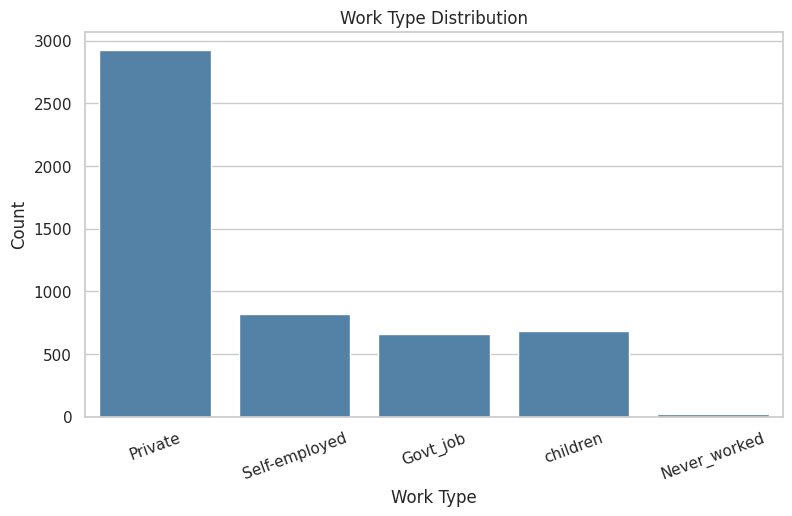

In [ ]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="work_type", color="steelblue")
plt.title("Work Type Distribution")
plt.xlabel("Work Type")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.show()

**Observation: work type.** Private-sector employment is the most common category (2,925), followed by self-employment (819), children (687) and government employment (657). `"Never_worked"` has only 22 observations. Because work type has several meaningful categories, it needs categorical (one-hot) encoding before it is passed to the models.

#### Residence Type

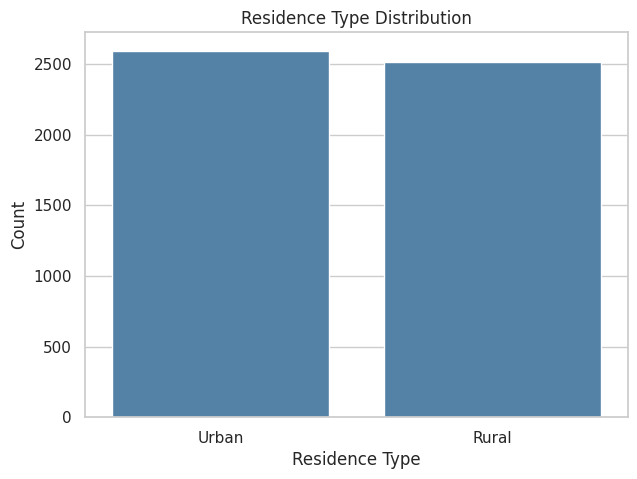

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Residence_type", color="steelblue")
plt.title("Residence Type Distribution")
plt.xlabel("Residence Type")
plt.ylabel("Count")
plt.show()

**Observation: residence type.** Urban (2,596) and rural (2,514) observations are roughly balanced. The variable is kept and one-hot encoded. Whether it carries any signal for stroke is judged by the model results.

#### Smoking Status

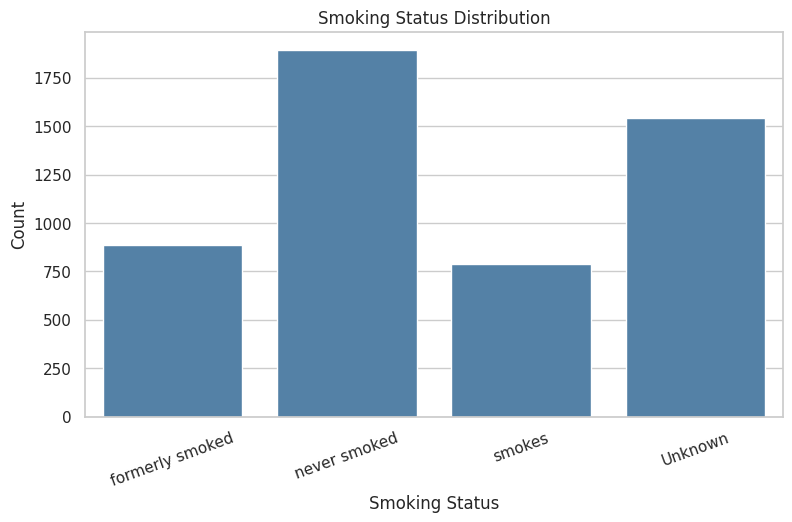

In [ ]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="smoking_status", color="steelblue")
plt.title("Smoking Status Distribution")
plt.xlabel("Smoking Status")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.show()

**Observation: smoking status.** `"never smoked"` is the largest category (1,892), followed by `"Unknown"` (1,544), `"formerly smoked"` (885) and `"smokes"` (789). A large share of observations is `"Unknown"`. This label means smoking information was not available, which is not the same as a missing numerical value, so it is kept as its own category and one-hot encoded.

### 4.3 Relationships With the Target

#### Correlation Heatmap

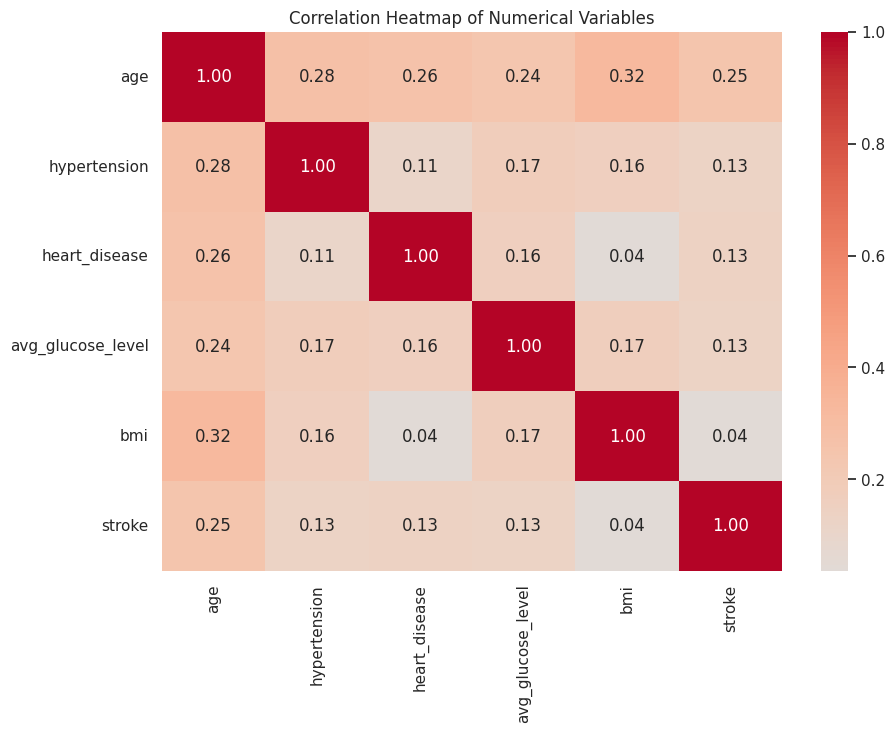

In [ ]:
# Pearson correlation between all numerical variables (including the stroke target)
correlation_matrix = df.select_dtypes(include="number").corr()

plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

**Observation: correlations.** Age has the strongest linear association with stroke among the numerical variables (about 0.25), although this is still weak. Heart disease, average glucose level and hypertension have smaller positive associations (about 0.13 each), and BMI has a much weaker one (about 0.04).

These correlations do not show causation. A weak linear correlation also does not make a feature useless, because machine-learning models can find non-linear or interaction effects. The potentially relevant predictors are therefore kept for modelling.

#### Age vs Stroke

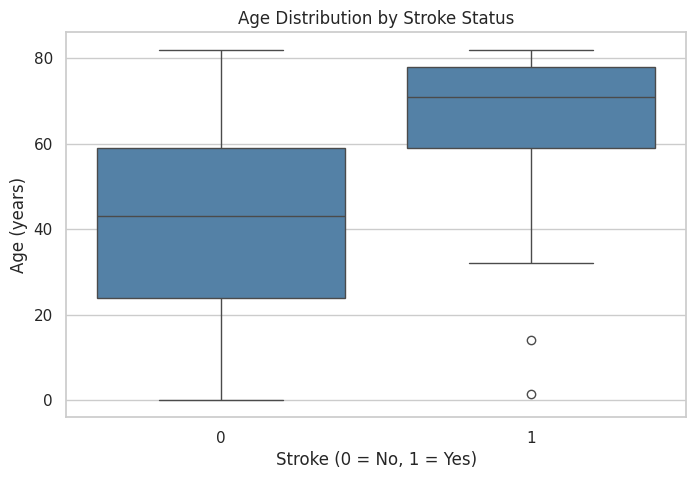

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="stroke", y="age", color="steelblue")
plt.title("Age Distribution by Stroke Status")
plt.xlabel("Stroke (0 = No, 1 = Yes)")
plt.ylabel("Age (years)")
plt.show()

**Observation: age and stroke.** The stroke group is clearly older than the non-stroke group (median age about 71 compared with about 43). This agrees with the correlation analysis, where age had the strongest association with stroke, so age is expected to be an important predictor.

#### Glucose Level vs Stroke

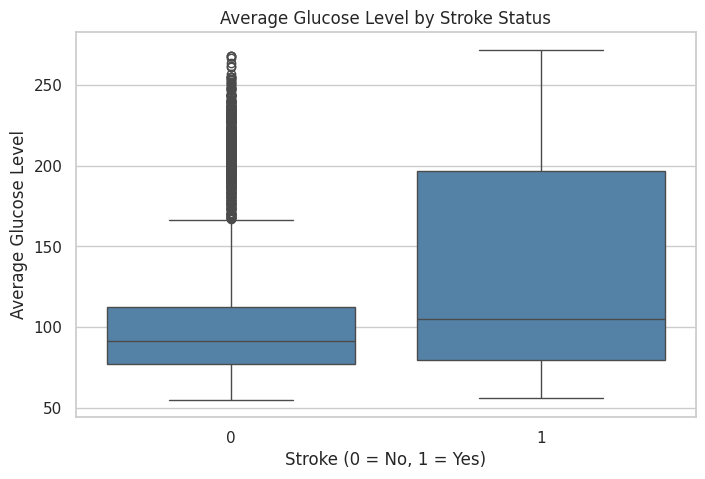

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="stroke", y="avg_glucose_level", color="steelblue")
plt.title("Average Glucose Level by Stroke Status")
plt.xlabel("Stroke (0 = No, 1 = Yes)")
plt.ylabel("Average Glucose Level")
plt.show()

**Observation: glucose and stroke.** The stroke group generally has higher average glucose levels than the non-stroke group (median about 105 compared with about 91), but the two distributions overlap substantially. Glucose level may therefore add useful information, but it cannot separate the classes on its own.

## 5. Data Preprocessing

For modelling, the notebook returns to `raw_df`, which keeps the source data from before the exploratory imputation and the removal of `id`. The steps are:

1. Separate the target (`stroke`) from the features, and remove the `id` identifier.
2. Split into training and test sets (80% / 20%, stratified so both sets keep the same stroke rate).
3. Build a preprocessing pipeline that fills missing values, scales numerical features and one-hot encodes categorical features. It is **fitted on the training data only** and then applied to the test data.
4. Handle class imbalance through class weights (no resampling).

Doing the split **first** and fitting every preprocessing step on the training set only prevents data leakage from the test set.

### 5.1 Train/Test Split

In [ ]:
# Features (everything except the target and the identifier) and the target
X = raw_df.drop(columns=["stroke", "id"])
y = raw_df["stroke"].astype(int)

# 80/20 split. stratify=y keeps the stroke rate the same in both sets, and
# random_state makes the split reproducible.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training features shape:", X_train.shape)
print("Test features shape:    ", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())
print("\nTest target distribution:")
print(y_test.value_counts().sort_index())

Training features shape: (4088, 10)
Test features shape:     (1022, 10)

Training target distribution:
stroke
0    3889
1     199
Name: count, dtype: int64

Test target distribution:
stroke
0    972
1     50
Name: count, dtype: int64


### 5.2 Preprocessing Pipeline

- **Numerical features** are filled with the training-set **median** (this is where the missing BMI values are handled) and then standardised to mean 0 and standard deviation 1.
- **Categorical features** are filled with their most frequent training value (a safeguard; there are no missing categories in this dataset) and one-hot encoded. `handle_unknown="ignore"` lets the pipeline cope with a category that appears in the test set but not in training.
- **Class imbalance:** Logistic Regression, Decision Tree and Random Forest use `class_weight="balanced"`. XGBoost uses `scale_pos_weight`, the ratio of non-stroke to stroke cases, calculated from the training split only.

Each model gets its own copy of the pipeline (via `clone`), so no preprocessing step is ever fitted on the test set.

In [ ]:
# Column groups, taken from the training features
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

# Numerical branch: fill missing values with the training median, then standardise
numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Categorical branch: fill with the most frequent value, then one-hot encode
categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

# Apply each branch to its own columns
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features),
])

# Class weight for XGBoost: ratio of non-stroke to stroke cases in the TRAINING set
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
scale_pos_weight = negative_count / positive_count

print("Numeric features:    ", numeric_features)
print("Categorical features:", categorical_features)
print(f"XGBoost scale_pos_weight (from training split): {scale_pos_weight:.3f}")

Numeric features:     ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']
Categorical features: ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
XGBoost scale_pos_weight (from training split): 19.543


## 6. Model Training

Four models are trained on the same training set and evaluated on the same stratified test set: Logistic Regression, Decision Tree, Random Forest and XGBoost. Settings are fixed, sensible defaults, and **no hyperparameter tuning was done**, so this is a comparison of baseline models.

In [ ]:
# Each model is a pipeline: preprocessing first, then the classifier.
# clone(preprocessor) gives every model its own unfitted copy of the preprocessing.
models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42)),
    ]),
    "Decision Tree": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", DecisionTreeClassifier(class_weight="balanced", random_state=42)),
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            class_weight="balanced", n_estimators=200, random_state=42, n_jobs=-1)),
    ]),
    "XGBoost": Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", XGBClassifier(
            scale_pos_weight=scale_pos_weight,   # up-weights the rare stroke class
            n_estimators=200,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.9,
            colsample_bytree=0.9,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1,
        )),
    ]),
}

# Fit every pipeline on the training data only
for model_name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{model_name}: training complete")

Logistic Regression: training complete
Decision Tree: training complete
Random Forest: training complete
XGBoost: training complete


In [ ]:
import joblib

joblib.dump(models["Decision Tree"], "decision_tree_pipeline.joblib")
joblib.dump(models["Random Forest"], "random_forest_pipeline.joblib")
joblib.dump(models["XGBoost"], "xgboost_pipeline.joblib")
joblib.dump(models["Logistic Regression"], "logistic_regression_pipeline.joblib")

from google.colab import files

for filename in [
    "decision_tree_pipeline.joblib",
    "random_forest_pipeline.joblib",
    "xgboost_pipeline.joblib",
    "logistic_regression_pipeline.joblib",
]:
    files.download(filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Model Evaluation

All four models are evaluated on the same stratified test set: 1,022 patients, of whom 972 had no stroke and 50 had a stroke. For each model, the notebook reports accuracy, precision, recall and F1-score for each class, the confusion matrix, and two threshold-independent scores (ROC-AUC and PR-AUC).

Because only about 5% of patients had a stroke, a model that always predicts "no stroke" scores about 95% accuracy. Accuracy alone is therefore not enough, so the stroke class (class 1) is the main focus. A missed stroke (false negative) is treated as the more serious error. This is an educational comparison, not a clinical tool.

### 7.1 Calculating the Metrics

The cell below loops over the four trained models and, for each one, calculates predictions, the confusion matrix, precision, recall and F1-score for both classes, accuracy, ROC-AUC and PR-AUC.

- **Precision** = of the patients predicted to have a stroke, the share who really did. **Recall** = of the patients who really had a stroke, the share the model caught. **F1-score** = the harmonic mean of precision and recall.
- **ROC-AUC and PR-AUC** use predicted probabilities, so they judge how well a model *ranks* patients regardless of the 0.5 cut-off.
- A 95% **Wilson confidence interval** (Wilson, 1927) is added to stroke recall because the test set contains only 50 stroke cases.
- Two baselines are printed for context: the accuracy of always predicting "no stroke", and the stroke rate in the test set (the precision of random guessing).

In [ ]:
# All four trained models in one place so they can be evaluated in a loop
trained_models = {name: model for name, model in models.items()}
CLASS_NAMES = {0: "No stroke (0)", 1: "Stroke (1)"}


def wilson_interval(successes, n, z=1.96):
    """95% Wilson confidence interval for a proportion (used for stroke recall)."""
    p = successes / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half


confusion_matrices, scores = {}, {}
summary_rows, class_rows = [], []

for name, model in trained_models.items():
    # Class predictions (0.5 cut-off) and predicted stroke probabilities
    y_pred = model.predict(X_test)
    y_score = model.predict_proba(X_test)[:, 1]
    scores[name] = y_score

    # Confusion matrix: rows = actual class, columns = predicted class.
    # ravel() returns true negatives, false positives, false negatives, true positives.
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    confusion_matrices[name] = cm
    tn, fp, fn, tp = cm.ravel()

    # Precision, recall, F1-score and support for each class (index 0 and 1).
    # zero_division=0 avoids a warning when a model never predicts a class.
    precision, recall, f1, support = precision_recall_fscore_support(
        y_test, y_pred, labels=[0, 1], zero_division=0
    )

    # Uncertainty of stroke recall: the real stroke cases are tp + fn
    ci_low, ci_high = wilson_interval(tp, tp + fn)

    # One row per model for the overall comparison table
    summary_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Stroke precision": precision[1],
        "Stroke recall": recall[1],
        "Stroke F1": f1[1],
        "Stroke recall 95% CI": f"{ci_low:.2f} to {ci_high:.2f}",
        "Macro F1": f1.mean(),
        "ROC-AUC": roc_auc_score(y_test, y_score),
        "PR-AUC": average_precision_score(y_test, y_score),
        "TP": tp, "FN": fn, "FP": fp, "TN": tn,
    })

    # Two rows per model (one per class) for the per-class table
    for label in (0, 1):
        class_rows.append({
            "Model": name,
            "Class": CLASS_NAMES[label],
            "Precision": precision[label],
            "Recall": recall[label],
            "F1-score": f1[label],
            "Support": int(support[label]),
        })

summary_df = pd.DataFrame(summary_rows)
class_df = pd.DataFrame(class_rows)

# Reference points for judging the results
majority_accuracy = (y_test == 0).mean()   # accuracy of always predicting "no stroke"
stroke_prevalence = y_test.mean()          # precision of random guessing

print(f"Test set: {len(y_test)} patients ({int(y_test.sum())} stroke cases)")
print(f"Baseline accuracy (always predict 'no stroke'): {majority_accuracy:.4f}")
print(f"Stroke prevalence (precision of random guessing): {stroke_prevalence:.4f}\n")

print("Overall comparison (TP/FN/FP/TN = confusion-matrix counts for the stroke class):")
display(summary_df.round(4))
print("\nPer-class precision, recall and F1-score:")
display(class_df.round(4))

Test set: 1022 patients (50 stroke cases)
Baseline accuracy (always predict 'no stroke'): 0.9511
Stroke prevalence (precision of random guessing): 0.0489

Overall comparison (TP/FN/FP/TN = confusion-matrix counts for the stroke class):


,Model,Accuracy,Stroke precision,Stroke recall,Stroke F1,Stroke recall 95% CI,Macro F1,ROC-AUC,PR-AUC,TP,FN,FP,TN
0,Logistic Regression,0.7456,0.1379,0.80,0.2353,0.67 to 0.89,0.5414,0.8437,0.2685,40,10,250,722
1,Decision Tree,0.9286,0.1892,0.14,0.1609,0.07 to 0.26,0.5618,0.5546,0.0686,7,43,30,942
2,Random Forest,0.9501,0.0000,0.00,0.0000,0.00 to 0.07,0.4872,0.7614,0.1299,0,50,1,971
3,XGBoost,0.8366,0.1872,0.70,0.2954,0.56 to 0.81,0.6015,0.8319,0.2361,35,15,152,820



Per-class precision, recall and F1-score:


,Model,Class,Precision,Recall,F1-score,Support
0,Logistic Regression,No stroke (0),0.9863,0.7428,0.8474,972
1,Logistic Regression,Stroke (1),0.1379,0.8000,0.2353,50
2,Decision Tree,No stroke (0),0.9563,0.9691,0.9627,972
3,Decision Tree,Stroke (1),0.1892,0.1400,0.1609,50
4,Random Forest,No stroke (0),0.9510,0.9990,0.9744,972
5,Random Forest,Stroke (1),0.0000,0.0000,0.0000,50
6,XGBoost,No stroke (0),0.9820,0.8436,0.9076,972
7,XGBoost,Stroke (1),0.1872,0.7000,0.2954,50


### 7.2 Confusion Matrices

Rows are the **actual** class and columns are the **predicted** class. The bottom-left cell is the number of stroke cases the model missed (false negatives). The first grid shows counts. The second shows the share of each actual class, so the bottom-right value is the stroke recall. The second grid is useful because raw counts are dominated by the large non-stroke class.

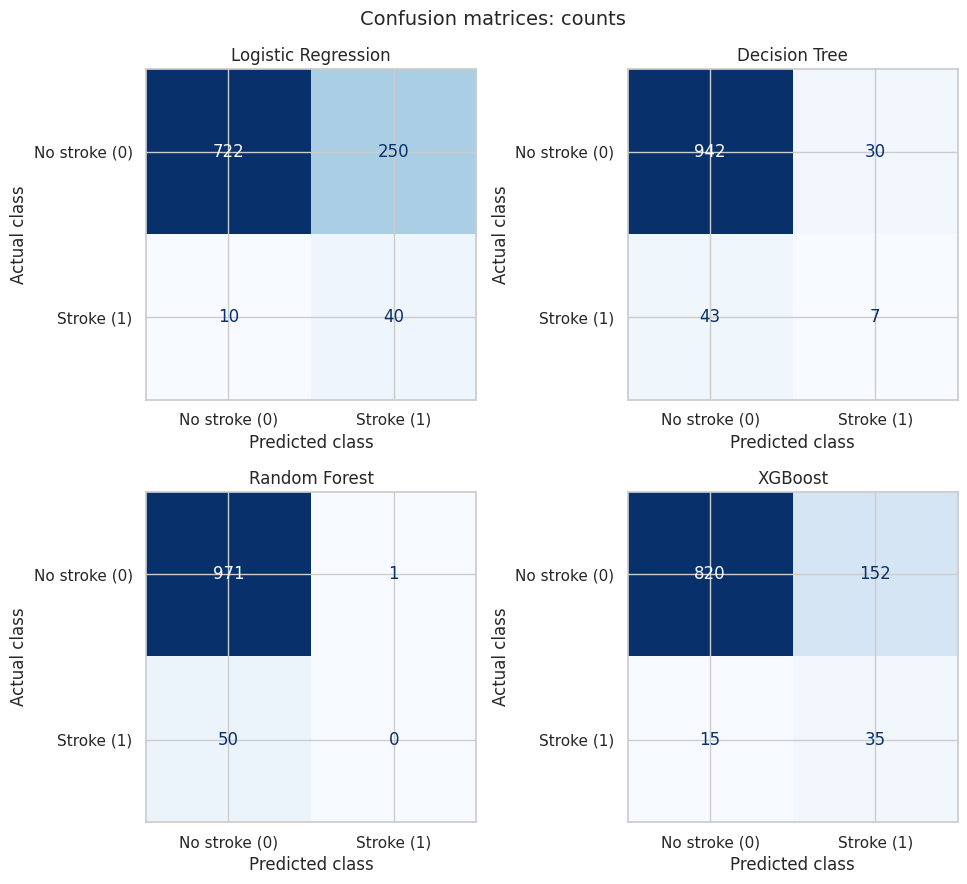

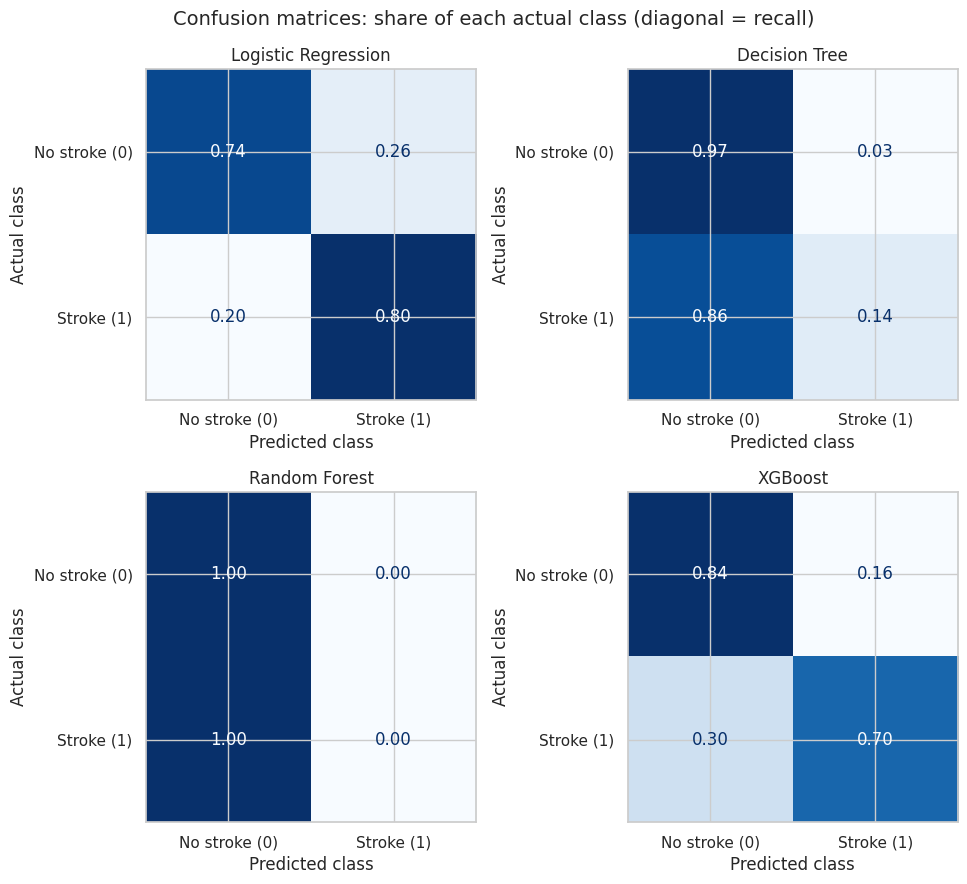

In [ ]:
labels = [CLASS_NAMES[0], CLASS_NAMES[1]]

# Draw the same 2x2 grid twice: first with counts, then with row-normalised values
grid_configs = [
    ("Confusion matrices: counts", False),
    ("Confusion matrices: share of each actual class (diagonal = recall)", True),
]
for title, normalise in grid_configs:
    fig, axes = plt.subplots(2, 2, figsize=(10, 9))

    # One panel per model
    for ax, (name, cm) in zip(axes.ravel(), confusion_matrices.items()):
        # Normalising divides each row by its total, so each row sums to 1
        values = cm / cm.sum(axis=1, keepdims=True) if normalise else cm
        ConfusionMatrixDisplay(values, display_labels=labels).plot(
            ax=ax, cmap="Blues", colorbar=False,
            values_format=".2f" if normalise else "d",
        )
        ax.set_title(name)
        ax.set_xlabel("Predicted class")
        ax.set_ylabel("Actual class")

    fig.suptitle(title, fontsize=14)
    fig.tight_layout()
    plt.show()

### 7.3 Visual Model Comparison

The bar chart compares stroke-class precision, recall and F1-score across the four models. The ROC and precision-recall curves show how well each model separates stroke from non-stroke patients across **all** possible thresholds, not only at 0.5. On the precision-recall plot, the dashed line is the performance of random guessing; a curve that stays close to it has little ranking ability.

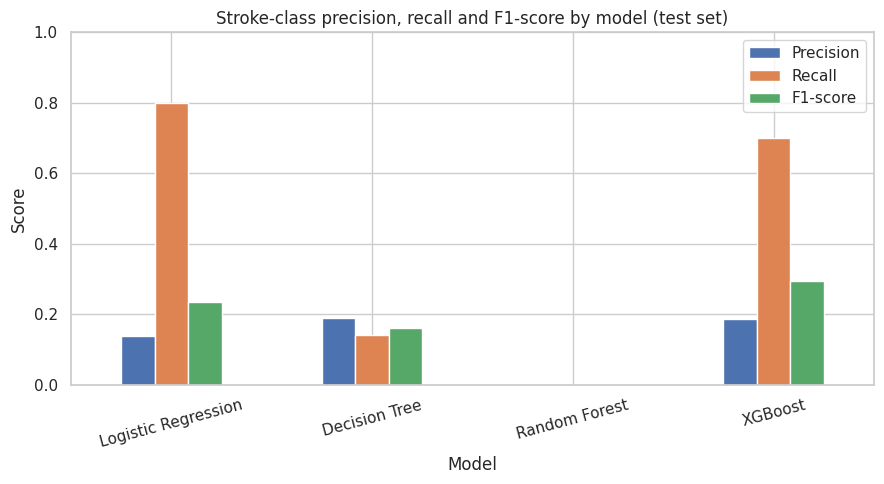

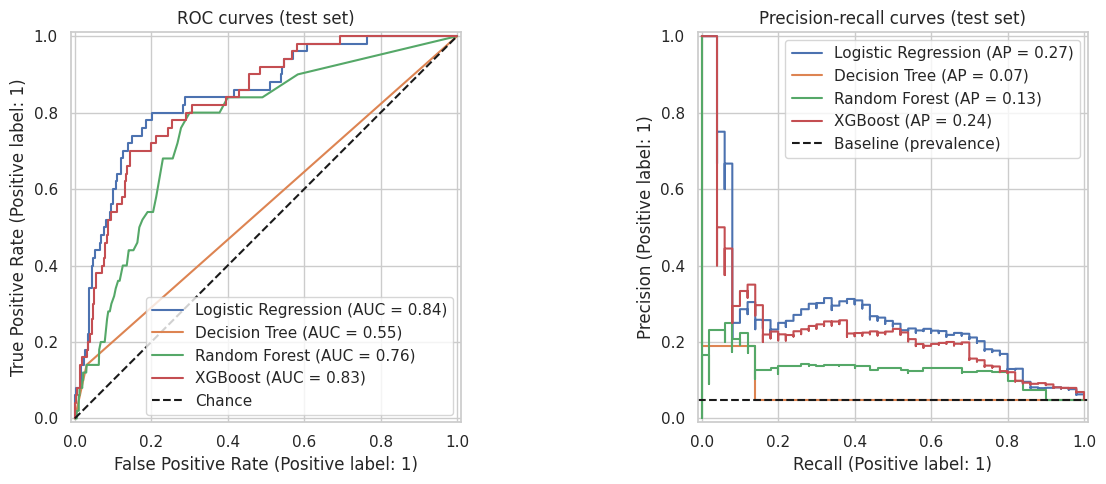

In [ ]:
# Stroke-class (class 1) precision, recall and F1-score for each model
stroke_metrics = (
    class_df[class_df["Class"] == CLASS_NAMES[1]]
    .set_index("Model")[["Precision", "Recall", "F1-score"]]
)

# Grouped bar chart of the three metrics
ax = stroke_metrics.plot(kind="bar", figsize=(9, 5), ylim=(0, 1))
ax.set_title("Stroke-class precision, recall and F1-score by model (test set)")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
plt.xticks(rotation=15)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

# ROC curves (left) and precision-recall curves (right), all four models on each
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, y_score in scores.items():
    RocCurveDisplay.from_predictions(y_test, y_score, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, y_score, name=name, ax=axes[1])

# Reference lines: chance level for ROC, stroke prevalence for precision-recall
axes[0].plot([0, 1], [0, 1], "k--", label="Chance")
axes[0].set_title("ROC curves (test set)")
axes[1].axhline(stroke_prevalence, color="k", linestyle="--", label="Baseline (prevalence)")
axes[1].set_title("Precision-recall curves (test set)")
for ax in axes:
    ax.legend(loc="best")
plt.tight_layout()
plt.show()

### 7.4 Results Summary

The cell below reads the tables above and writes a short summary of which model scored highest on each metric. It also flags any model whose accuracy is no better than always predicting "no stroke", and any model that never predicted a stroke. Because the text is generated from the results, it stays correct if the notebook is re-run.

In [ ]:
# Index the summary table by model name for easy lookup
s = summary_df.set_index("Model")

# Models that never predicted stroke (no true or false positives at the 0.5 cut-off)
no_stroke_predicted = [m for m in s.index if s.loc[m, "TP"] + s.loc[m, "FP"] == 0]

# Models no more accurate than predicting "no stroke" for everyone
at_or_below_baseline = [m for m in s.index if s.loc[m, "Accuracy"] <= majority_accuracy]

# Build the summary as a list of markdown lines
best_recall_model = s["Stroke recall"].idxmax()
lines = [
    "#### Results summary (generated from the tables above)",
    f"- **Highest stroke recall:** {best_recall_model} ({s['Stroke recall'].max():.2f}; "
    f"{int(s.loc[best_recall_model, 'FN'])} missed stroke cases).",
    f"- **Highest stroke precision:** {s['Stroke precision'].idxmax()} ({s['Stroke precision'].max():.2f}).",
    f"- **Highest stroke F1-score:** {s['Stroke F1'].idxmax()} ({s['Stroke F1'].max():.2f}).",
    f"- **Highest PR-AUC (ranking quality, independent of threshold):** {s['PR-AUC'].idxmax()} "
    f"({s['PR-AUC'].max():.3f}; random guessing = {stroke_prevalence:.3f}).",
    f"- **Highest ROC-AUC:** {s['ROC-AUC'].idxmax()} ({s['ROC-AUC'].max():.3f}).",
    f"- **Highest accuracy:** {s['Accuracy'].idxmax()} ({s['Accuracy'].max():.4f}); "
    f"always predicting 'no stroke' scores {majority_accuracy:.4f}.",
]

# Add warnings only when they apply
if at_or_below_baseline:
    lines.append("- **Accuracy at or below the do-nothing baseline:** " + ", ".join(at_or_below_baseline) + ".")
if no_stroke_predicted:
    lines.append("- **Never predicted stroke at the default 0.5 threshold:** " + ", ".join(no_stroke_predicted) + ".")
lines.append(
    "- **Test-set uncertainty:** the 95% intervals for stroke recall are wide, "
    "so small gaps between models are not reliable."
)

# Render the lines as formatted markdown
display(Markdown("\n".join(lines)))

#### Results summary (generated from the tables above)
- **Highest stroke recall:** Logistic Regression (0.80; 10 missed stroke cases).
- **Highest stroke precision:** Decision Tree (0.19).
- **Highest stroke F1-score:** XGBoost (0.30).
- **Highest PR-AUC (ranking quality, independent of threshold):** Logistic Regression (0.269; random guessing = 0.049).
- **Highest ROC-AUC:** Logistic Regression (0.844).
- **Highest accuracy:** Random Forest (0.9501); always predicting 'no stroke' scores 0.9511.
- **Accuracy at or below the do-nothing baseline:** Logistic Regression, Decision Tree, Random Forest, XGBoost.
- **Test-set uncertainty:** the 95% intervals for stroke recall are wide, so small gaps between models are not reliable.

### 7.5 Head-to-Head: Logistic Regression vs XGBoost

Only two of the four models detect strokes usefully (see the discussion in section 8): Logistic Regression and XGBoost. The table below places them side by side. TP and FN are caught and missed strokes; FP are false alarms; TN are correctly cleared patients.

In [ ]:
# Side-by-side comparison of the two models that detect strokes
head_to_head_models = ["Logistic Regression", "XGBoost"]
head_to_head_metrics = [
    "Accuracy", "Stroke precision", "Stroke recall", "Stroke F1", "Macro F1",
    "ROC-AUC", "PR-AUC", "TP", "FN", "FP", "TN",
]

head_to_head = summary_df.set_index("Model").loc[head_to_head_models, head_to_head_metrics].T
head_to_head = head_to_head.astype(object)  # lets counts show as whole numbers and rates as decimals

# Round the rates to 4 decimals and show the confusion-matrix counts as integers
for metric in head_to_head.index:
    if metric in ("TP", "FN", "FP", "TN"):
        head_to_head.loc[metric] = head_to_head.loc[metric].astype(int)
    else:
        head_to_head.loc[metric] = head_to_head.loc[metric].astype(float).round(4)

display(head_to_head)

Model,Logistic Regression,XGBoost
Accuracy,0.7456,0.8366
Stroke precision,0.1379,0.1872
Stroke recall,0.8,0.7
Stroke F1,0.2353,0.2954
Macro F1,0.5414,0.6015
ROC-AUC,0.8437,0.8319
PR-AUC,0.2685,0.2361
TP,40,35
FN,10,15
FP,250,152


### 7.6 Check: Do the Written Results Match This Run?

The discussion in section 8 quotes numbers from a reference run. Results from Logistic Regression, the Decision Tree and the Random Forest are reproducible with the fixed random seeds, but small differences between library versions (especially XGBoost) can shift a count by a few cases. The cell below compares this run with the numbers quoted in section 8 and tells you if any text needs updating.

In [ ]:
# (true positives, false positives) quoted in the written discussion in section 8
quoted_results = {
    "Logistic Regression": (40, 250),
    "Decision Tree": (7, 30),
    "Random Forest": (0, 1),
    "XGBoost": (35, 152),
}

all_match = True
for name, (quoted_tp, quoted_fp) in quoted_results.items():
    row = summary_df.set_index("Model").loc[name]
    if (int(row["TP"]), int(row["FP"])) != (quoted_tp, quoted_fp):
        all_match = False
        print(f"DIFFERENT for {name}: this run TP={int(row['TP'])}, FP={int(row['FP'])} "
              f"(section 8 quotes TP={quoted_tp}, FP={quoted_fp}).")

if all_match:
    print("OK: this run matches the numbers quoted in section 8.")
else:
    print("\nUpdate the numbers in section 8 so they match the tables above.")

OK: this run matches the numbers quoted in section 8.


## 8. Model Comparison and Discussion

### 8.1 How to Read the Results

- **Accuracy** is misleading here. Only 4.9% of test patients had a stroke, so always predicting "no stroke" scores 0.9511 (Saito & Rehmsmeier, 2015).
- **Stroke recall** is the share of the 50 real stroke cases a model caught. A missed stroke is the most serious error in this problem.
- **Stroke precision** is the share of stroke predictions that were correct. Random guessing would score about 0.049.
- **ROC-AUC and PR-AUC** measure how well a model ranks patients by risk, independent of the 0.5 cut-off. PR-AUC is the more informative of the two on imbalanced data (Saito & Rehmsmeier, 2015).

### 8.2 Model Comparison

| Model | Strokes caught (of 50) | Stroke recall (95% CI) | Stroke precision | Stroke F1 | False alarms (FP) | ROC-AUC | PR-AUC | Accuracy |
|---|---|---|---|---|---|---|---|---|
| Logistic Regression | 40 | 0.80 (0.67 to 0.89) | 0.138 | 0.235 | 250 | 0.844 | 0.269 | 0.746 |
| XGBoost | 35 | 0.70 (0.56 to 0.81) | 0.187 | 0.295 | 152 | 0.832 | 0.236 | 0.837 |
| Decision Tree | 7 | 0.14 (0.07 to 0.26) | 0.189 | 0.161 | 30 | 0.555 | 0.069 | 0.929 |
| Random Forest | 0 | 0.00 (0.00 to 0.07) | 0.000 | 0.000 | 1 | 0.761 | 0.130 | 0.950 |

**1. Accuracy ranks the models in exactly the opposite order to stroke recall.** Random Forest has the highest accuracy (0.950) and caught no strokes. Logistic Regression has the lowest accuracy (0.746) and caught the most. No model beat the 0.9511 baseline of always predicting "no stroke"; Random Forest is slightly below it because its one stroke prediction was wrong. Accuracy should therefore not be used to choose a model on this dataset.

**2. Only Logistic Regression and XGBoost detect strokes usefully.** Both reach a PR-AUC about 5 times the random baseline (0.269 and 0.236 against 0.049) and catch 70% to 80% of strokes. They make different trade-offs:

- Logistic Regression caught 5 more strokes than XGBoost (40 against 35) but raised 98 more false alarms (250 against 152).
- XGBoost has the highest F1-score (0.295), the highest macro F1 (0.602) and the better balance between missed strokes and false alarms.
- Logistic Regression ranks patients slightly better (higher ROC-AUC and PR-AUC) and is the simpler, more interpretable model.
- These gaps are small. The recall intervals overlap (0.67 to 0.89 against 0.56 to 0.81), and one stroke case moves recall by 2 percentage points. The data does not show that either model is better.

**3. The Decision Tree is close to random.** It caught 7 of 50 strokes. Its ROC-AUC of 0.555 is near chance (0.5) and its PR-AUC of 0.069 is barely above the 0.049 baseline. Its precision of 0.189 looks like the highest, but it rests on only 37 stroke predictions and is almost identical to XGBoost's 0.187, so it is not a meaningful advantage.

**4. Random Forest fails at the 0.5 cut-off, not at ranking.** It predicted stroke only once, and wrongly. Its ROC-AUC (0.761) and PR-AUC (0.130, about 2.7 times the baseline) show that it does rank stroke patients above others to some extent. Its predicted probabilities for the rare class simply almost never reach 0.5, so its result at the default threshold is not a fair measure of what the model could do.

**5. Every model produces mostly false alarms.** Even the best precision is 0.19, about 4 times better than guessing but still low. About 86% of Logistic Regression's stroke predictions were wrong (250 of 290), and about 81% of XGBoost's (152 of 187). Catching most strokes with these models means accepting many false positives.

**Conclusion.** Logistic Regression and XGBoost are the two candidates, and the choice between them depends on the cost of each error. If missing a stroke is much worse than a false alarm, Logistic Regression catches more strokes. If false alarms matter too, XGBoost gives the better balance. Given only 50 stroke cases and overlapping intervals, neither can be declared the winner. The Decision Tree and Random Forest should not be used in their current form.

### 8.3 Strengths and Weaknesses

| Model | Strengths | Weaknesses |
|---|---|---|
| Logistic Regression | Highest recall (0.80), ROC-AUC and PR-AUC. Simple, fast and interpretable. Class weights push it towards catching strokes. | Lowest accuracy (0.746) and the most false alarms (250). A linear boundary cannot capture interactions such as age with hypertension. |
| Decision Tree | Easy to explain as rules. Can capture non-linear patterns. Few false alarms (30). | Caught only 7 of 50 strokes and ranks almost at chance. With no depth limit it is likely to overfit (this fits the results but was not checked against training scores). Unstable across different samples. |
| Random Forest | Ranks patients better than the single tree (ROC-AUC 0.761 against 0.555), as averaging many trees reduces variance (Breiman, 2001). | Predicted stroke once and caught none at the 0.5 cut-off. It looks accurate (0.950) only because the data is imbalanced. Harder to interpret. |
| XGBoost | Best F1-score (0.295) and macro F1. Caught 70% of strokes with 98 fewer false alarms than Logistic Regression. Can model non-linear effects and interactions (Chen & Guestrin, 2016). | Recall is lower than Logistic Regression's. Settings were not tuned, and there are only 199 training stroke cases. Less interpretable. |

### 8.4 Limitations

- All models are untuned baselines evaluated at the default 0.5 decision threshold, so the results show how the models behave out of the box, not their best possible performance.
- One train/test split with 50 stroke cases gives high-variance results.
- The data comes from a public Kaggle dataset (Fedesoriano, 2021) with limited documentation about how it was collected.
- This is an educational project and must not be used for diagnosis or treatment decisions.

### 8.5 What Could Be Improved

1. **Choose the decision threshold, not just the model.** Random Forest ranks patients reasonably but never crosses 0.5, and Logistic Regression and XGBoost make very different recall and false-alarm trade-offs at the same cut-off. Select the threshold on validation data or out-of-fold predictions, based on how costly a missed stroke is compared with a false alarm. Keep the test set untouched until the end.
2. **Tune hyperparameters with stratified cross-validation on the training data only**, and select on recall or PR-AUC rather than accuracy. Examples: limit tree depth and minimum leaf size for the Decision Tree, use `class_weight="balanced_subsample"` and a minimum leaf size for Random Forest, tune depth, learning rate and regularisation for XGBoost, and tune the regularisation strength for Logistic Regression.
3. **Use repeated stratified cross-validation to report the spread of each metric.** With 50 test stroke cases, the XGBoost recall interval spans 0.56 to 0.81, which is too wide to rank close models.
4. **Reduce the false-alarm rate.** With 81% to 86% false alarms, even the best models would need a follow-up step to be useful. Compare class weighting with resampling applied only inside the training folds (He & Garcia, 2009), and check probability calibration.
5. **Improve the inputs.** Check whether missing BMI is related to stroke and, if so, add a missing-value indicator. Check performance across age, sex and other subgroups.
6. **Validate externally.** These results come from one split of one public dataset. The models must not be used to diagnose or guide treatment without validation on an independent, representative dataset and clinical review.

## 9. References

Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5-32. https://doi.org/10.1023/A:1010933404324

Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 785-794. https://doi.org/10.1145/2939672.2939785

Fedesoriano. (2021). *Stroke prediction dataset* [Data set]. Kaggle. https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

Harris, C. R., Millman, K. J., van der Walt, S. J., et al. (2020). Array programming with NumPy. *Nature, 585*, 357-362. https://doi.org/10.1038/s41586-020-2649-2

He, H., & Garcia, E. A. (2009). Learning from imbalanced data. *IEEE Transactions on Knowledge and Data Engineering, 21*(9), 1263-1284. https://doi.org/10.1109/TKDE.2008.239

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90-95. https://doi.org/10.1109/MCSE.2007.55

McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th Python in Science Conference*, 56-61.

Pedregosa, F., Varoquaux, G., Gramfort, A., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.

Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE, 10*(3), e0118432. https://doi.org/10.1371/journal.pone.0118432

scikit-learn developers. (n.d.). *ColumnTransformer*. https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html

scikit-learn developers. (n.d.). *Confusion matrix*. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html

scikit-learn developers. (n.d.). *Model evaluation: Quantifying the quality of predictions*. https://scikit-learn.org/stable/modules/model_evaluation.html

scikit-learn developers. (n.d.). *Pipeline*. https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html

Waskom, M. L. (2021). seaborn: Statistical data visualization. *Journal of Open Source Software, 6*(60), 3021. https://doi.org/10.21105/joss.03021

Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *Journal of the American Statistical Association, 22*(158), 209-212.

XGBoost developers. (n.d.). *XGBoost documentation*. https://xgboost.readthedocs.io/

**Reference check:** confirm the citation style required by your course rubric, and click each DOI/link to verify titles, volumes and pages before submission.